# 04. Model Comparison — Klasifikasi Jenis Wine

Notebook ini menyajikan perbandingan hasil klasifikasi dari notebook 03. Notebook 03 menghitung evaluasi; notebook ini membaca hasil holdout dan cross-validation yang diekspor, lalu menyusun tabel dan visualisasi. Jalankan notebook 03 dari atas sampai sel terakhir terlebih dahulu.

## 1. Memuat Hasil Evaluasi

Hasil holdout berasal dari satu split test yang digunakan bersama oleh seluruh model. Hasil cross-validation final memakai outer 5-fold pada data latih; pencarian `k` KNN berlangsung di inner 5-fold setiap outer fold. Kedua evaluasi ditampilkan berdampingan untuk memberi gambaran hasil test dan variasi CV.

In [15]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.ticker import PercentFormatter

PROJECT_ROOT = Path.cwd()
while not (PROJECT_ROOT / "data" / "processed" / "winequality_cleaned.csv").is_file():
    if PROJECT_ROOT.parent == PROJECT_ROOT:
        raise FileNotFoundError("winequality_cleaned.csv tidak ditemukan. Jalankan notebook dari proyek Wine.")
    PROJECT_ROOT = PROJECT_ROOT.parent

REPORT_DIR = PROJECT_ROOT / "reports" / "classification"
test_path = REPORT_DIR / "classification_test_metrics.csv"
cv_path = REPORT_DIR / "classification_cv_metrics.csv"
missing_files = [path.name for path in (test_path, cv_path) if not path.is_file()]
if missing_files:
    raise FileNotFoundError(
        "Hasil evaluasi belum tersedia: " + ", ".join(missing_files) + ". "
        "Jalankan notebook 03 dari atas sampai sel terakhir agar file dibuat di "
        f"{REPORT_DIR}."
    )

test_results = pd.read_csv(test_path)
cv_results = pd.read_csv(cv_path)
required_test = {"Model", "Accuracy", "Precision Macro", "Recall Macro", "F1-score Macro"}
required_cv = {"Model", "Accuracy Mean", "Accuracy Std", "Precision Macro Mean", "Recall Macro Mean", "F1 Macro Mean", "F1 Macro Std"}
if not required_test.issubset(test_results.columns) or not required_cv.issubset(cv_results.columns):
    raise ValueError("Format file hasil evaluasi tidak sesuai. Jalankan ulang notebook 03.")
if set(test_results["Model"]) != set(cv_results["Model"]):
    raise ValueError("Daftar model pada hasil holdout dan CV berbeda. Jalankan ulang notebook 03.")

comparison = test_results.merge(
    cv_results, on="Model", how="inner", validate="one_to_one",
)
comparison = comparison.sort_values("F1-score Macro", ascending=False).reset_index(drop=True)
print("Sumber hasil:", REPORT_DIR)
print("Hasil holdout pada satu split test:")
display(test_results.style.format({
    "Accuracy": "{:.3%}", "Precision Macro": "{:.3%}",
    "Recall Macro": "{:.3%}", "F1-score Macro": "{:.3%}",
}))
print("Hasil nested cross-validation pada data latih:")
display(cv_results.style.format({
    "Accuracy Mean": "{:.3%}", "Accuracy Std": "{:.3%}",
    "Precision Macro Mean": "{:.3%}", "Recall Macro Mean": "{:.3%}",
    "F1 Macro Mean": "{:.3%}", "F1 Macro Std": "{:.3%}",
}))

Sumber hasil: d:\MachineLearning\Wine\reports\classification
Hasil holdout pada satu split test:


,Model,Accuracy,Precision Macro,Recall Macro,F1-score Macro,Selected k
0,KNN (tuned),99.624%,99.626%,99.385%,99.505%,1.000000
1,Random Forest,99.342%,99.194%,99.075%,99.135%,nan
2,Logistic Regression,99.248%,98.898%,99.133%,99.015%,nan
3,Decision Tree,97.838%,96.901%,97.462%,97.177%,nan


Hasil nested cross-validation pada data latih:


,Model,Accuracy Mean,Accuracy Std,Precision Macro Mean,Precision Macro Std,Recall Macro Mean,Recall Macro Std,F1 Macro Mean,F1 Macro Std,CV Design
0,Random Forest,99.553%,0.251%,99.489%,0.001761,99.337%,0.005414,99.410%,0.335%,5-fold outer CV; nested 5-fold KNN tuning
1,Logistic Regression,99.294%,0.197%,99.134%,0.001467,99.011%,0.004779,99.070%,0.264%,5-fold outer CV; nested 5-fold KNN tuning
2,KNN (tuned),99.153%,0.417%,98.861%,0.006212,98.917%,0.005019,98.888%,0.546%,5-fold outer CV; nested 5-fold KNN tuning
3,Decision Tree,98.048%,0.463%,97.290%,0.006172,97.599%,0.006776,97.440%,0.610%,5-fold outer CV; nested 5-fold KNN tuning


## 2. Perbandingan Skor per Metrik

Empat panel memisahkan Accuracy, Precision Macro, Recall Macro, dan F1 Macro. Setiap model menampilkan skor holdout dan rata-rata outer CV; whisker CV menunjukkan simpangan baku antar-fold bila tersedia. Setelah notebook 03 dijalankan ulang, seluruh panel akan menyertakan simpangan baku. Rentang sumbu diperbesar untuk keterbacaan dan ditandai pada tiap panel.

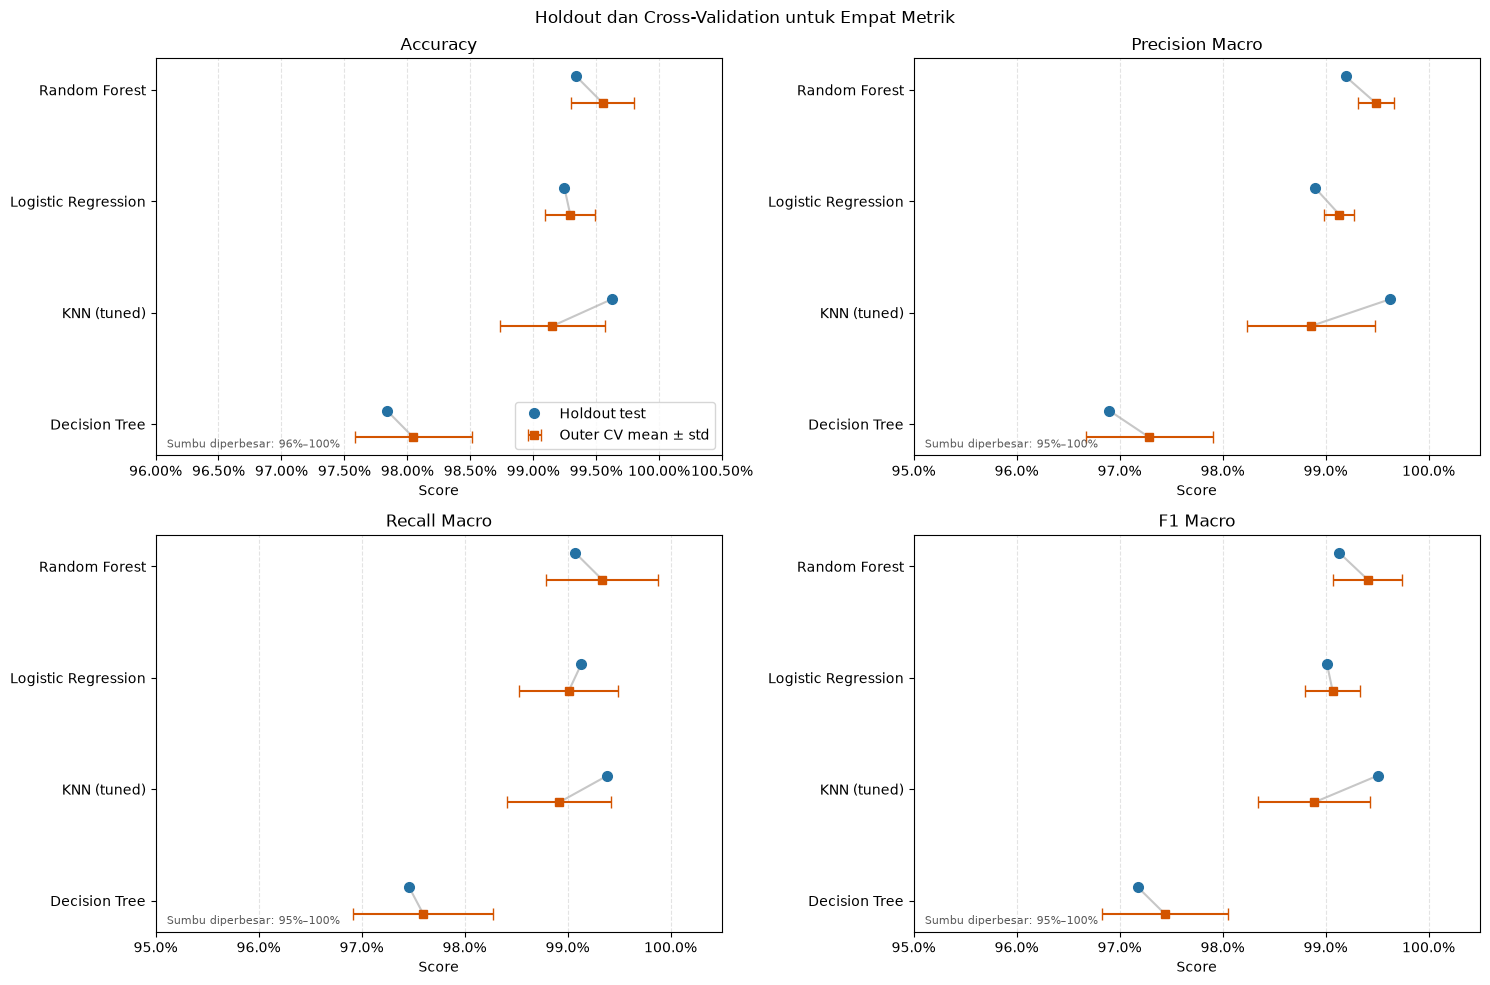

In [16]:
plot_specs = [
    ("Accuracy", "Accuracy Mean", "Accuracy Std", "Accuracy"),
    ("Precision Macro", "Precision Macro Mean", "Precision Macro Std", "Precision Macro"),
    ("Recall Macro", "Recall Macro Mean", "Recall Macro Std", "Recall Macro"),
    ("F1-score Macro", "F1 Macro Mean", "F1 Macro Std", "F1 Macro"),
]
plot_data = comparison.sort_values("F1 Macro Mean", ascending=True).reset_index(drop=True)
fig, axes = plt.subplots(2, 2, figsize=(15, 10))

for panel, (ax, (test_col, cv_mean, cv_std, title)) in enumerate(zip(axes.flat, plot_specs)):
    y = np.arange(len(plot_data))
    holdout = plot_data[test_col].to_numpy()
    cv_values = plot_data[cv_mean].to_numpy()
    cv_std_values = (
        plot_data[cv_std].to_numpy()
        if cv_std in plot_data.columns
        else None
    )

    for row, test_score, cv_score in zip(y, holdout, cv_values):
        ax.plot(
            [test_score, cv_score], [row + 0.12, row - 0.12],
            color="0.78", linewidth=1.5, zorder=1,
        )
    ax.errorbar(
        holdout, y + 0.12, fmt="o", markersize=7,
        color="#2471A3", label="Holdout test", zorder=3,
    )
    ax.errorbar(
        cv_values, y - 0.12, xerr=cv_std_values, fmt="s", markersize=6,
        color="#D35400", ecolor="#D35400", capsize=4,
        label="Outer CV mean ± std", zorder=3,
    )

    ax.set_title(title)
    ax.set_xlabel("Score")
    ax.xaxis.set_major_formatter(PercentFormatter(xmax=1))
    ax.set_yticks(y)
    ax.set_yticklabels(plot_data["Model"])
    ax.grid(axis="x", linestyle="--", alpha=0.35)
    cv_lower = cv_values if cv_std_values is None else cv_values - cv_std_values
    lowest = min(float(holdout.min()), float(cv_lower.min()))
    lower_limit = max(0.0, np.floor((lowest - 0.015) * 100) / 100)
    ax.set_xlim(lower_limit, 1.005)
    ax.text(
        0.02, 0.02, f"Sumbu diperbesar: {lower_limit:.0%}–100%",
        transform=ax.transAxes, fontsize=8, color="0.35",
    )
    if panel == 0:
        ax.legend(loc="lower right")

fig.suptitle("Holdout dan Cross-Validation untuk Empat Metrik")
fig.tight_layout()
plt.show()

## 3. Heatmap Selisih Holdout dan Rata-rata CV

Heatmap menunjukkan selisih holdout dikurangi rata-rata CV dalam poin persentase. Nilai positif berarti skor holdout lebih tinggi; nilai negatif berarti lebih rendah. Baca sebagai perbandingan deskriptif karena test hanya satu split dan CV memiliki variasi antar-fold.


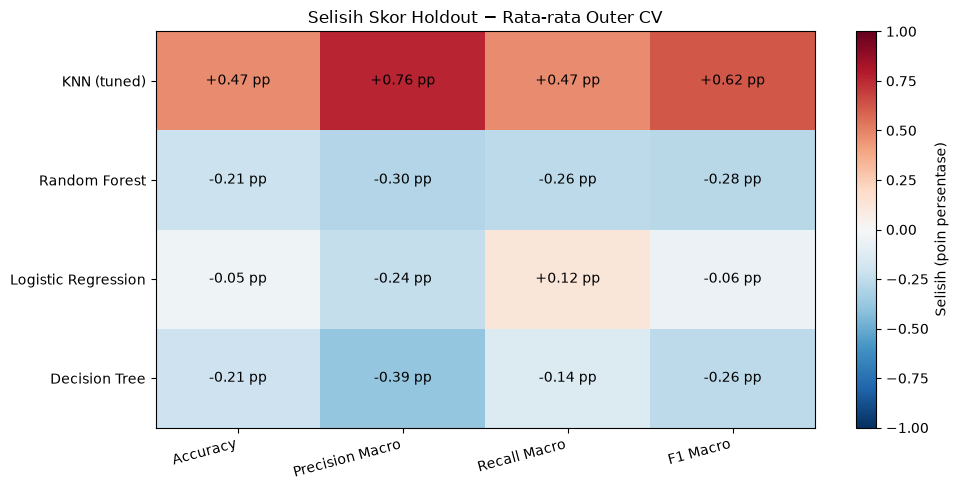

In [17]:
gap_columns = {
    "Accuracy": ("Accuracy", "Accuracy Mean"),
    "Precision Macro": ("Precision Macro", "Precision Macro Mean"),
    "Recall Macro": ("Recall Macro", "Recall Macro Mean"),
    "F1 Macro": ("F1-score Macro", "F1 Macro Mean"),
}
gap_data = pd.DataFrame(index=comparison["Model"])
for metric, (holdout_col, cv_col) in gap_columns.items():
    gap_data[metric] = (
        comparison[holdout_col].to_numpy() - comparison[cv_col].to_numpy()
    ) * 100

max_gap = max(0.5, float(np.ceil(gap_data.abs().to_numpy().max() * 2) / 2))
fig, ax = plt.subplots(figsize=(10, 5))
image = ax.imshow(
    gap_data.to_numpy(), cmap="RdBu_r", vmin=-max_gap, vmax=max_gap, aspect="auto"
)
ax.set_xticks(np.arange(len(gap_data.columns)))
ax.set_xticklabels(gap_data.columns, rotation=15, ha="right")
ax.set_yticks(np.arange(len(gap_data.index)))
ax.set_yticklabels(gap_data.index)
ax.set_title("Selisih Skor Holdout − Rata-rata Outer CV")
for row in range(gap_data.shape[0]):
    for col in range(gap_data.shape[1]):
        value = gap_data.iloc[row, col]
        ax.text(col, row, f"{value:+.2f} pp", ha="center", va="center", fontsize=10)
colorbar = fig.colorbar(image, ax=ax)
colorbar.set_label("Selisih (poin persentase)")
fig.tight_layout()
plt.show()

## 4. Chart Peringkat F1 Macro

Chart batang menyusun model menurut rata-rata F1 Macro outer CV. Batang holdout menunjukkan hasil pada satu split test; error bar CV menunjukkan simpangan baku antar-fold. Sumbu Y dipersempit untuk memperjelas perbedaan dan rentangnya ditandai.


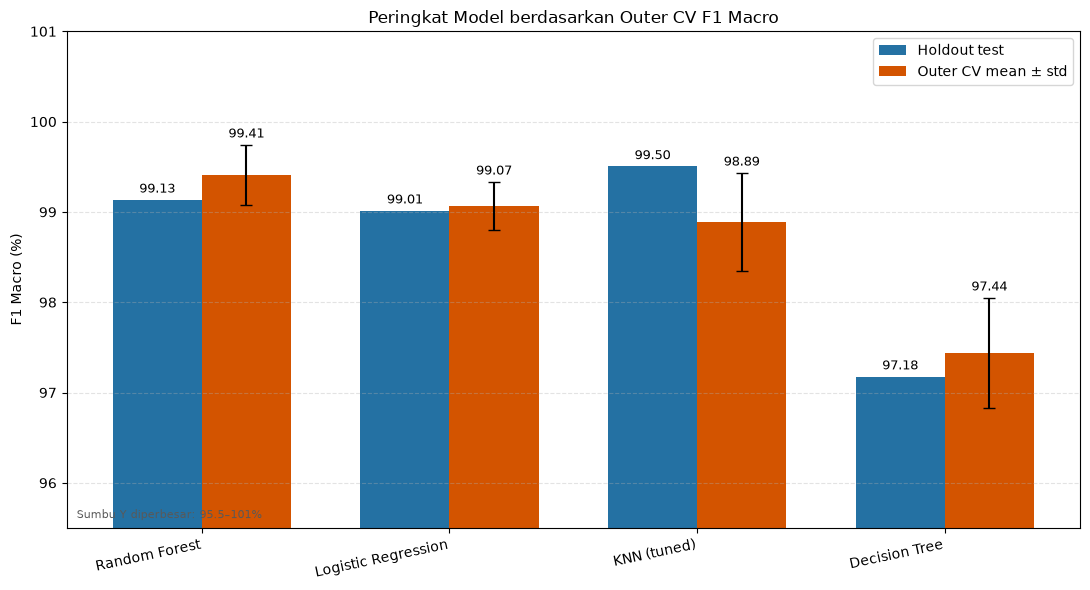

In [18]:
chart_data = cv_results.sort_values("F1 Macro Mean", ascending=False).merge(
    test_results[["Model", "F1-score Macro"]],
    on="Model", how="inner", validate="one_to_one",
).reset_index(drop=True)

x = np.arange(len(chart_data))
width = 0.36
holdout_scores = chart_data["F1-score Macro"].to_numpy() * 100
cv_scores = chart_data["F1 Macro Mean"].to_numpy() * 100
cv_errors = chart_data["F1 Macro Std"].to_numpy() * 100

fig, ax = plt.subplots(figsize=(11, 6))
bars_holdout = ax.bar(
    x - width / 2, holdout_scores, width,
    label="Holdout test", color="#2471A3",
)
bars_cv = ax.bar(
    x + width / 2, cv_scores, width,
    yerr=cv_errors, capsize=4,
    label="Outer CV mean ± std", color="#D35400",
)
ax.bar_label(bars_holdout, fmt="%.2f", padding=3, fontsize=9)
ax.bar_label(bars_cv, fmt="%.2f", padding=3, fontsize=9)
ax.set_xticks(x)
ax.set_xticklabels(chart_data["Model"], rotation=12, ha="right")
ax.set_ylabel("F1 Macro (%)")
ax.set_title("Peringkat Model berdasarkan Outer CV F1 Macro")
ax.grid(axis="y", linestyle="--", alpha=0.35)
ax.legend()
lowest = min(float(holdout_scores.min()), float((cv_scores - cv_errors).min()))
y_min = max(0.0, np.floor((lowest - 1.0) * 2) / 2)
ax.set_ylim(y_min, 101)
ax.text(
    0.01, 0.02, f"Sumbu Y diperbesar: {y_min:.1f}–101%",
    transform=ax.transAxes, fontsize=8, color="0.35",
)
fig.tight_layout()
plt.show()

## 5. Cara Membaca Hasil

Tabel menampilkan nilai tepat untuk setiap metrik; empat panel memperlihatkan skor holdout dan CV serta variasi antar-fold bila tersedia; heatmap menunjukkan selisih holdout terhadap rata-rata CV dalam poin persentase; chart batang merangkum peringkat F1 Macro. Holdout adalah satu split, sedangkan CV merangkum beberapa outer fold. Selisih tersebut bersifat deskriptif, bukan uji signifikansi atau skor gabungan.